In [1]:
import requests
import zipfile
import io

url = "https://github.com/anikets95/bmtc-data/archive/refs/heads/main.zip"

response = requests.get(url)
response.raise_for_status()

zip_file = zipfile.ZipFile(io.BytesIO(response.content))
zip_file.extractall("/content/bmtc_data")

print("BMTC dataset downloaded successfully!")

BMTC dataset downloaded successfully!


In [2]:
import os

for root, dirs, files in os.walk("/content/bmtc_data"):
    for file in files[:10]:
        print(file)

.gitignore
README.md
LICENSE.md
bmtc.zip
missingShapes.txt
missingTimetables.txt
bmtc.zip
missingStops.txt
validation-results.html
system_errors.json
report.html
report.json
validation.json
config.json
system-map.js
timetable-map.js
timetable-menu.js
timetable_styles.css
timetable_pdf_styles.css
overview_styles.css
2ge11111110_yhkot-vnc-blr_0_mon-sun.html
27o11111110_104-sdnibk-kbs_0_mon-sun.html
8011111110_415-b_0_mon-sun.html
4p11111110_500-qd-ybs-csb_0_mon-sun.html
1p411111110_285-k_0_mon-sun.html
k611111110_365-d-bvh-d34_0_mon-sun.html
18y11111110_345-e-d34g-bgr-ank_0_mon-sun.html
v311111111_500-d-d10g-hblb_1_mon-sun.html
15w11111110_323-b_0_mon-sun.html
gc11111110_215-x_0_mon-sun.html
stops.csv
routes.csv
aggregated.csv
stops.geojson
routes.geojson
aggregated.geojson
routeids.zip
routelines.zip
timetables.zip
stops.zip


In [3]:
import os

base_path = "/content/bmtc_data"

print("Folders and files:")

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)

    print("  " * level + os.path.basename(root) + "/")

    for file in files:
        print("  " * (level + 1) + file)

Folders and files:
bmtc_data/
  bmtc-data-main/
    .gitignore
    README.md
    LICENSE.md
    gtfs/
      bmtc.zip
      intermediate/
        missingShapes.txt
        missingTimetables.txt
        bmtc.zip
        missingStops.txt
    validation/
      gtfsvtor/
        validation-results.html
      gtfs-validator/
        system_errors.json
        report.html
        report.json
      transport-validator/
        validation.json
    html/
      config.json
      bmtc/
        js/
          system-map.js
          timetable-map.js
          timetable-menu.js
        css/
          timetable_styles.css
          timetable_pdf_styles.css
          overview_styles.css
        20241107-20241113/
          2ge11111110_yhkot-vnc-blr_0_mon-sun.html
          27o11111110_104-sdnibk-kbs_0_mon-sun.html
          8011111110_415-b_0_mon-sun.html
          4p11111110_500-qd-ybs-csb_0_mon-sun.html
          1p411111110_285-k_0_mon-sun.html
          k611111110_365-d-bvh-d34_0_mon-sun.html
     

In [4]:
readme_path = None

for root, dirs, files in os.walk(base_path):
    if "README.md" in files:
        readme_path = os.path.join(root, "README.md")
        break

if readme_path:
    with open(readme_path, "r") as f:
        print(f.read()[:5000])

# bmtc-data

This is unofficial data from bmtc website : https://bmtcwebportal.amnex.com/. 

Please check the website for recent and updated data.

Intention of this repo is to host data scraped and parsed by : https://github.com/anikets95/bmtc-gtfs

Please read through this [README](https://github.com/anikets95/bmtc-gtfs/blob/main/README.md)


In [5]:
import os

for root, dirs, files in os.walk("/content/bmtc_data"):
    for file in files:
        if file.endswith((".csv", ".txt", ".json")):
            print(file)

missingShapes.txt
missingTimetables.txt
missingStops.txt
system_errors.json
report.json
validation.json
config.json
stops.csv
routes.csv
aggregated.csv


In [6]:
import glob
import os

html_files = glob.glob(
    "/content/bmtc_data/**/*.html",
    recursive=True
)

print("Total HTML files:", len(html_files))

# Select one timetable file
sample_file = html_files[0]

print("\nSample file:", os.path.basename(sample_file))

with open(sample_file, "r", encoding="utf-8") as f:
    html_content = f.read()

print("\nFile content:")
print(html_content[:3000])

Total HTML files: 4072

Sample file: validation-results.html

File content:
<!DOCTYPE html>

<html lang="en">
	<head>
		<meta charset="UTF-8"/>
		<title>GTFS validation report
		</title>
		<style type="text/css">
body {
	font-family: Arial, Helvetica, sans-serif;
}

hr {
	border: 1px solid #212f3d;
}

.INFO {
	background-color: #a9cce3;
}

.WARNING {
	background-color: #f7dc6f;
}

.ERROR {
	background-color: #f5b7b1;
}

.CRITICAL {
	background-color: #c0392b;
}

.badge {
	font-weight: bold;
	padding-left: 0.2em;
	padding-right: 0.2em;
	margin-left: 0.2em;
	margin-right: 0.2em;
	border-radius: 0.4em;
}

.smaller {
	font-size: 80%;
}

.xsmaller {
	font-size: 60%;
}

.comments {
	color: #888888;
}

span.tablename {
	font-family: monospace;
	border-radius: 0.2em;
	background-color: #eaecee;
	padding-left: 0.2em;
	padding-right: 0.2em;
}

div.subcategory {
	border-top: dashed 1px;
	padding-top: 0.4em;
	margin-bottom: 1em;
}

table.sourceinfo {
	border-collapse: collapse;
	border: none;
	fon

In [7]:
import pandas as pd
import os

base_path = "/content/bmtc_data"

for filename in ["stops.csv", "routes.csv", "aggregated.csv"]:

    file_path = None

    for root, dirs, files in os.walk(base_path):
        if filename in files:
            file_path = os.path.join(root, filename)
            break

    if file_path:
        df = pd.read_csv(file_path)

        print("\n", "=" * 50)
        print("FILE:", filename)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        display(df.head(5))


FILE: stops.csv
Shape: (8305, 5)
Columns: ['name', 'trip_count', 'route_count', 'id', 'geometry']


,name,trip_count,route_count,id,geometry
0,(Theneyuru)I Basapura Gate,24,1,168,POINT (77.83624 13.22602)
1,10th Cross Magadi Road,345,47,58n,POINT (77.55706 12.97574)
2,10th Cross Magadi Road,566,79,zp,POINT (77.55562 12.97556)
3,10th Stone NICE Road,64,2,17,POINT (77.4986 12.87273)
4,10th Stone NICE Road,86,11,cm,POINT (77.49865 12.87242)



FILE: routes.csv
Shape: (4009, 7)
Columns: ['name', 'full_name', 'trip_count', 'stop_count', 'id', 'direction_id', 'geometry']


,name,full_name,trip_count,stop_count,id,direction_id,geometry
0,D43-SVP,Shivanapura → Depot-43 Gate,1,3,1,1,"LINESTRING (77.421524 13.049264, 77.42123 13.0..."
1,VNS-014,CS-Vidyaniketan School Hebbala → CS-Sanjayanag...,1,2,10,1,"LINESTRING (77.596436 13.047558, 77.59643 13.0..."
2,314,Shivajinagara Bus Station → CV Raman Nagara,1,21,100,0,"LINESTRING (77.60323 12.98396, 77.60327 12.984..."
3,253-G,Chikka Banavara → Yeshawanthapura Bus Station,5,21,101,1,"LINESTRING (77.4314 13.20187, 77.43206 13.2023..."
4,ITPL-2J,CS-ITPL → CS-Vidyaranyapura,1,2,102,1,"LINESTRING (77.74665 12.985857, 77.74744 12.98..."



FILE: aggregated.csv
Shape: (4655, 4)
Columns: ['name', 'trip_count', 'route_count', 'geometry']


,name,trip_count,route_count,geometry
0,(Theneyuru)I Basapura Gate,24,1,POINT (77.83624 13.22602)
1,10th Cross Magadi Road,911,126,POINT (77.55706 12.97574)
2,10th Stone NICE Road,150,13,POINT (77.4986 12.87273)
3,11th Block Anjanapura,7,3,POINT (77.57235 12.85225)
4,12th Block Nagarabhavi,352,44,POINT (77.51398 12.96018)


In [8]:
import pandas as pd
import os

datasets = {}

for filename in ["stops.csv", "routes.csv", "aggregated.csv"]:

    for root, dirs, files in os.walk("/content/bmtc_data"):
        if filename in files:
            path = os.path.join(root, filename)
            datasets[filename] = pd.read_csv(path)
            break

for name, data in datasets.items():

    print("\nDataset:", name)
    print("Shape:", data.shape)

    print("\nData types:")
    print(data.dtypes)

    print("\nMissing values:")
    print(data.isnull().sum())

    print("\nDuplicate rows:", data.duplicated().sum())


Dataset: stops.csv
Shape: (8305, 5)

Data types:
name           object
trip_count      int64
route_count     int64
id             object
geometry       object
dtype: object

Missing values:
name           0
trip_count     0
route_count    0
id             0
geometry       0
dtype: int64

Duplicate rows: 0

Dataset: routes.csv
Shape: (4009, 7)

Data types:
name            object
full_name       object
trip_count       int64
stop_count       int64
id              object
direction_id     int64
geometry        object
dtype: object

Missing values:
name            0
full_name       0
trip_count      0
stop_count      0
id              0
direction_id    0
geometry        0
dtype: int64

Duplicate rows: 0

Dataset: aggregated.csv
Shape: (4655, 4)

Data types:
name           object
trip_count      int64
route_count     int64
geometry       object
dtype: object

Missing values:
name           0
trip_count     0
route_count    0
geometry       0
dtype: int64

Duplicate rows: 0


In [9]:
for name, data in datasets.items():

    print("\nDataset:", name)

    print(data.describe())


Dataset: stops.csv
        trip_count  route_count
count  8305.000000  8305.000000
mean    103.551595    12.635641
std     198.834010    23.008547
min       1.000000     1.000000
25%       4.000000     2.000000
50%      19.000000     4.000000
75%     120.000000    13.000000
max    4858.000000   483.000000

Dataset: routes.csv
        trip_count   stop_count  direction_id
count  4009.000000  4009.000000   4009.000000
mean      8.304066    25.958344      0.450237
std      18.444476    16.297356      0.497580
min       1.000000     1.000000      0.000000
25%       1.000000    13.000000      0.000000
50%       2.000000    25.000000      0.000000
75%       5.000000    38.000000      1.000000
max     162.000000    95.000000      1.000000

Dataset: aggregated.csv
        trip_count  route_count
count  4655.000000  4655.000000
mean    184.746724    22.543287
std     389.306830    44.641375
min       1.000000     1.000000
25%       4.000000     2.000000
50%      27.000000     6.000000
75%     

In [10]:
import os
import zipfile

zip_path = None

for root, dirs, files in os.walk("/content/bmtc_data"):
    if "bmct.zip" in files:
        zip_path = os.path.join(root, "bmct.zip")
        break

if zip_path:
    with zipfile.ZipFile(zip_path, "r") as z:
        files = z.namelist()

        print("Total files:", len(files))
        print("\nImportant transport files:")

        for file in files:
            if file.endswith((".txt", ".csv")):
                print(file)
else:
    print("bmct.zip not found")

bmct.zip not found


In [11]:
import os

for root, dirs, files in os.walk("/content/bmtc_data"):
    for file in files:
        if file.lower().endswith(".zip"):
            print(os.path.join(root, file))

/content/bmtc_data/bmtc-data-main/gtfs/bmtc.zip
/content/bmtc_data/bmtc-data-main/gtfs/intermediate/bmtc.zip
/content/bmtc_data/bmtc-data-main/raw/routeids.zip
/content/bmtc_data/bmtc-data-main/raw/routelines.zip
/content/bmtc_data/bmtc-data-main/raw/timetables.zip
/content/bmtc_data/bmtc-data-main/raw/stops.zip


In [12]:
import zipfile

zip_path = "/content/bmtc_data/bmtc-data-main/gtfs/bmtc.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()

    print("Total files:", len(files))
    print("\nFiles inside GTFS archive:")

    for file in files[:50]:
        print(file)

Total files: 7

Files inside GTFS archive:
agency.txt
stops.txt
shapes.txt
routes.txt
calendar.txt
trips.txt
stop_times.txt


In [13]:
import pandas as pd
import zipfile

zip_path = "/content/bmtc_data/bmtc-data-main/gtfs/bmtc.zip"

with zipfile.ZipFile(zip_path, "r") as z:

    gtfs_data = {}

    for file in [
        "stops.txt",
        "routes.txt",
        "trips.txt",
        "stop_times.txt",
        "calendar.txt"
    ]:
        gtfs_data[file] = pd.read_csv(z.open(file))

        print(file, ":", gtfs_data[file].shape)

stops.txt : (8305, 4)
routes.txt : (3959, 5)
trips.txt : (34336, 6)
stop_times.txt : (859996, 5)
calendar.txt : (1, 10)


In [14]:
for name, data in gtfs_data.items():

    print("\n" + "=" * 40)
    print("DATASET:", name)

    print("\nColumns:")
    print(data.columns.tolist())

    print("\nFirst 3 rows:")
    display(data.head(3))


DATASET: stops.txt

Columns:
['stop_name', 'stop_id', 'stop_lat', 'stop_lon']

First 3 rows:


,stop_name,stop_id,stop_lat,stop_lon
0,(Theneyuru)I Basapura Gate,168,13.22602,77.83624
1,10th Cross Magadi Road,58n,12.97574,77.55706
2,10th Cross Magadi Road,zp,12.97556,77.55562



DATASET: routes.txt

Columns:
['route_long_name', 'route_short_name', 'agency_id', 'route_type', 'route_id']

First 3 rows:


,route_long_name,route_short_name,agency_id,route_type,route_id
0,11th Block Anjanapura ⇔ Vidhana Soudha,215-NE ANP11-KMT-VSD,1,3,1ba
1,11th Block Anjanapura ⇔ Vidhana Soudha,215-NE ANP11-MNRV-VSD,1,3,1p6
2,1st Block Vishweshwaraiah Layout ⇔ Kengeri Bus...,VLO1-KGR,1,3,2a3



DATASET: trips.txt

Columns:
['route_id', 'service_id', 'trip_headsign', 'direction_id', 'shape_id', 'trip_id']

First 3 rows:


,route_id,service_id,trip_headsign,direction_id,shape_id,trip_id
0,1,1,Depot-43 Gate,1,11p,mg1
1,10,1,CS-Sanjayanagara Vybhava Talkies,1,k0,bgn
2,100,1,Nagavarapalya,0,1e4,8hq



DATASET: stop_times.txt

Columns:
['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence']

First 3 rows:


,trip_id,arrival_time,departure_time,stop_id,stop_sequence
0,gf0,17:45:00,17:45:00,41c,1
1,gf0,17:47:00,17:47:00,5yq,2
2,gf0,17:49:00,17:49:00,2nu,3



DATASET: calendar.txt

Columns:
['monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date', 'service_id']

First 3 rows:


,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date,service_id
0,1,1,1,1,1,1,1,20241107,20241113,1


In [15]:
# Check whether IDs connect between datasets

trips = gtfs_data["trips.txt"]
stop_times = gtfs_data["stop_times.txt"]
stops = gtfs_data["stops.txt"]
routes = gtfs_data["routes.txt"]

print("Trips without matching routes:",
      (~trips["route_id"].isin(routes["route_id"])).sum())

print("Stop times without matching trips:",
      (~stop_times["trip_id"].isin(trips["trip_id"])).sum())

print("Stop times without matching stops:",
      (~stop_times["stop_id"].isin(stops["stop_id"])).sum())

print("\nCalendar information:")
display(gtfs_data["calendar.txt"])

Trips without matching routes: 0
Stop times without matching trips: 0
Stop times without matching stops: 0

Calendar information:


,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date,service_id
0,1,1,1,1,1,1,1,20241107,20241113,1


In [16]:
trips = gtfs_data["trips.txt"]
calendar = gtfs_data["calendar.txt"]

print("Unique service IDs in trips:")
print(trips["service_id"].unique())

print("\nUnique service IDs in calendar:")
print(calendar["service_id"].unique())

print("\nNumber of trips per service ID:")
print(trips["service_id"].value_counts())

print("\nCalendar date range:")
print("Start:", calendar["start_date"].min())
print("End:", calendar["end_date"].max())

Unique service IDs in trips:
[1]

Unique service IDs in calendar:
[1]

Number of trips per service ID:
service_id
1    34336
Name: count, dtype: int64

Calendar date range:
Start: 20241107
End: 20241113


In [17]:
for name, data in gtfs_data.items():
    print("\nDataset:", name)
    print("Missing values:")
    print(data.isnull().sum())
    print("Duplicate rows:", data.duplicated().sum())


Dataset: stops.txt
Missing values:
stop_name    0
stop_id      0
stop_lat     0
stop_lon     0
dtype: int64
Duplicate rows: 0

Dataset: routes.txt
Missing values:
route_long_name     0
route_short_name    0
agency_id           0
route_type          0
route_id            0
dtype: int64
Duplicate rows: 0

Dataset: trips.txt
Missing values:
route_id         0
service_id       0
trip_headsign    0
direction_id     0
shape_id         0
trip_id          1
dtype: int64
Duplicate rows: 0

Dataset: stop_times.txt
Missing values:
trip_id           32
arrival_time       0
departure_time     0
stop_id            0
stop_sequence      0
dtype: int64
Duplicate rows: 0

Dataset: calendar.txt
Missing values:
monday        0
tuesday       0
wednesday     0
thursday      0
friday        0
saturday      0
sunday        0
start_date    0
end_date      0
service_id    0
dtype: int64
Duplicate rows: 0


In [18]:
trips = gtfs_data["trips.txt"]
stop_times = gtfs_data["stop_times.txt"]

print("Trips with missing trip_id:")
display(trips[trips["trip_id"].isna()])

print("\nStop times with missing trip_id:")
display(stop_times[stop_times["trip_id"].isna()].head(10))

print("\nTotal missing trip IDs in trips:",
      trips["trip_id"].isna().sum())

print("Total missing trip IDs in stop_times:",
      stop_times["trip_id"].isna().sum())

Trips with missing trip_id:


,route_id,service_id,trip_headsign,direction_id,shape_id,trip_id
34067,zh,1,Kalkere,0,1jl,NaN



Stop times with missing trip_id:


,trip_id,arrival_time,departure_time,stop_id,stop_sequence
344669,NaN,09:25:00,09:25:00,2g9,1
344670,NaN,09:27:11,09:27:11,1pe,2
344671,NaN,09:29:22,09:29:22,5k5,3
344672,NaN,09:31:33,09:31:33,78,4
344673,NaN,09:33:45,09:33:45,14z,5
344674,NaN,09:35:56,09:35:56,ce,6
344675,NaN,09:38:07,09:38:07,4y2,7
344676,NaN,09:40:18,09:40:18,2pj,8
344677,NaN,09:42:30,09:42:30,1nc,9
344678,NaN,09:44:41,09:44:41,3pv,10



Total missing trip IDs in trips: 1
Total missing trip IDs in stop_times: 32


In [19]:
# Show records around the missing trip ID block

display(stop_times.iloc[344660:344710])

print("Missing trip ID row in trips:")
display(trips[trips["trip_id"].isna()])

,trip_id,arrival_time,departure_time,stop_id,stop_sequence
344660,ho4,15:55:18,15:55:18,4fz,24
344661,ho4,15:57:30,15:57:30,4n0,25
344662,ho4,15:59:41,15:59:41,21q,26
344663,ho4,16:01:52,16:01:52,6a3,27
344664,ho4,16:04:03,16:04:03,5u9,28
344665,ho4,16:06:15,16:06:15,4g5,29
344666,ho4,16:08:26,16:08:26,36c,30
344667,ho4,16:10:37,16:10:37,5hw,31
344668,ho4,16:12:48,16:12:48,5t,32
344669,NaN,09:25:00,09:25:00,2g9,1


Missing trip ID row in trips:


,route_id,service_id,trip_headsign,direction_id,shape_id,trip_id
34067,zh,1,Kalkere,0,1jl,NaN


In [20]:
missing_rows = stop_times[stop_times["trip_id"].isna()]

start = missing_rows.index.min()
end = missing_rows.index.max()

print("Missing rows:", len(missing_rows))
print("Starting index:", start)
print("Ending index:", end)

print("\nRecords before and after the missing block:")

display(stop_times.loc[start-3:end+3])

Missing rows: 32
Starting index: 344669
Ending index: 344700

Records before and after the missing block:


,trip_id,arrival_time,departure_time,stop_id,stop_sequence
344666,ho4,16:08:26,16:08:26,36c,30
344667,ho4,16:10:37,16:10:37,5hw,31
344668,ho4,16:12:48,16:12:48,5t,32
344669,NaN,09:25:00,09:25:00,2g9,1
344670,NaN,09:27:11,09:27:11,1pe,2
344671,NaN,09:29:22,09:29:22,5k5,3
344672,NaN,09:31:33,09:31:33,78,4
344673,NaN,09:33:45,09:33:45,14z,5
344674,NaN,09:35:56,09:35:56,ce,6
344675,NaN,09:38:07,09:38:07,4y2,7


In [21]:
print("First records around missing block:")
display(stop_times.iloc[start-2:start+2])

print("\nLast records around missing block:")
display(stop_times.iloc[end-1:end+3])S

First records around missing block:


,trip_id,arrival_time,departure_time,stop_id,stop_sequence
344667,ho4,16:10:37,16:10:37,5hw,31
344668,ho4,16:12:48,16:12:48,5t,32
344669,NaN,09:25:00,09:25:00,2g9,1
344670,NaN,09:27:11,09:27:11,1pe,2



Last records around missing block:


,trip_id,arrival_time,departure_time,stop_id,stop_sequence
344699,NaN,10:30:37,10:30:37,5hw,31
344700,NaN,10:32:48,10:32:48,5t,32
344701,osy,18:05:00,18:05:00,2g9,1
344702,osy,18:07:20,18:07:20,1pe,2


In [22]:
# Create copies without changing original datasets

clean_gtfs = {
    name: data.copy()
    for name, data in gtfs_data.items()
}

# Remove records with missing IDs
clean_gtfs["trips.txt"] = (
    clean_gtfs["trips.txt"].dropna(subset=["trip_id"])
)

clean_gtfs["stop_times.txt"] = (
    clean_gtfs["stop_times.txt"].dropna(subset=["trip_id"])
)

print("Cleaned dataset sizes:")

for name, data in clean_gtfs.items():
    print(name, data.shape)

Cleaned dataset sizes:
stops.txt (8305, 4)
routes.txt (3959, 5)
trips.txt (34335, 6)
stop_times.txt (859964, 5)
calendar.txt (1, 10)


In [23]:
trips = clean_gtfs["trips.txt"]
stop_times = clean_gtfs["stop_times.txt"]
routes = clean_gtfs["routes.txt"]
stops = clean_gtfs["stops.txt"]

print("Trips without matching routes:",
      (~trips["route_id"].isin(routes["route_id"])).sum())

print("Stop times without matching trips:",
      (~stop_times["trip_id"].isin(trips["trip_id"])).sum())

print("Stop times without matching stops:",
      (~stop_times["stop_id"].isin(stops["stop_id"])).sum())

print("\nRemaining missing values:")
for name, data in clean_gtfs.items():
    print(name, ":", data.isnull().sum().sum())

Trips without matching routes: 0
Stop times without matching trips: 0
Stop times without matching stops: 0

Remaining missing values:
stops.txt : 0
routes.txt : 0
trips.txt : 0
stop_times.txt : 0
calendar.txt : 0


In [24]:
# Start with scheduled stop-time records

analysis_df = clean_gtfs["stop_times.txt"].merge(
    clean_gtfs["trips.txt"],
    on="trip_id",
    how="left"
)

# Add route information

analysis_df = analysis_df.merge(
    clean_gtfs["routes.txt"],
    on="route_id",
    how="left"
)

# Add bus stop information

analysis_df = analysis_df.merge(
    clean_gtfs["stops.txt"],
    on="stop_id",
    how="left"
)

print("Final analysis table shape:", analysis_df.shape)

display(analysis_df.head())

Final analysis table shape: (859964, 17)


,trip_id,arrival_time,departure_time,stop_id,stop_sequence,route_id,service_id,trip_headsign,direction_id,shape_id,route_long_name,route_short_name,agency_id,route_type,stop_name,stop_lat,stop_lon
0,gf0,17:45:00,17:45:00,41c,1,1p6,1,11th Block Anjanapura,1,278,11th Block Anjanapura ⇔ Vidhana Soudha,215-NE ANP11-MNRV-VSD,1,3,Vidhana Soudha,12.98104,77.58853
1,gf0,17:47:00,17:47:00,5yq,2,1p6,1,11th Block Anjanapura,1,278,11th Block Anjanapura ⇔ Vidhana Soudha,215-NE ANP11-MNRV-VSD,1,3,Maharani College,12.97703,77.58580
2,gf0,17:49:00,17:49:00,2nu,3,1p6,1,11th Block Anjanapura,1,278,11th Block Anjanapura ⇔ Vidhana Soudha,215-NE ANP11-MNRV-VSD,1,3,KR Circle,12.97386,77.58661
3,gf0,17:51:00,17:51:00,607,4,1p6,1,11th Block Anjanapura,1,278,11th Block Anjanapura ⇔ Vidhana Soudha,215-NE ANP11-MNRV-VSD,1,3,St Marthas Hospital,12.96945,77.58716
4,gf0,17:53:00,17:53:00,3xv,5,1p6,1,11th Block Anjanapura,1,278,11th Block Anjanapura ⇔ Vidhana Soudha,215-NE ANP11-MNRV-VSD,1,3,Corporation,12.96480,77.58778


In [25]:
print("Analysis table shape:", analysis_df.shape)

print("\nMissing values:")
print(analysis_df.isnull().sum())

print("\nDuplicate rows:", analysis_df.duplicated().sum())

print("\nColumn names:")
print(analysis_df.columns.tolist())

Analysis table shape: (859964, 17)

Missing values:
trip_id             0
arrival_time        0
departure_time      0
stop_id             0
stop_sequence       0
route_id            0
service_id          0
trip_headsign       0
direction_id        0
shape_id            0
route_long_name     0
route_short_name    0
agency_id           0
route_type          0
stop_name           0
stop_lat            0
stop_lon            0
dtype: int64

Duplicate rows: 0

Column names:
['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence', 'route_id', 'service_id', 'trip_headsign', 'direction_id', 'shape_id', 'route_long_name', 'route_short_name', 'agency_id', 'route_type', 'stop_name', 'stop_lat', 'stop_lon']


In [26]:
# Count trips for each route

route_trips = (
    clean_gtfs["trips.txt"]
    .groupby("route_id")["trip_id"]
    .nunique()
    .reset_index(name="total_trips")
)

# Add route names

route_trips = route_trips.merge(
    clean_gtfs["routes.txt"][["route_id", "route_long_name", "route_short_name"]],
    on="route_id",
    how="left"
)

# Show the top 10 routes

top_routes = route_trips.sort_values(
    by="total_trips",
    ascending=False
).head(10)

display(top_routes)

,route_id,total_trips,route_long_name,route_short_name
624,1gu,323,Yelahanka Old Town ⇔ Peenya 2nd Stage,401-A
2643,2zd,305,Kempegowda Bus Station ⇔ Sir M Vishweshwaraiah...,300-MV
491,1d8,284,Yeshawanthapura Bus Station ⇔ Yelahanka Old Town,MF-401
2469,2uo,284,Mysore Road Bus Station ⇔ Hebbala,K-2
472,1cq,267,Kempegowda Bus Station ⇔ Shankarnagh Bus Stand,96-G
162,14c,265,Central Silk Board ⇔ Hebbala Bridge,V-500D
3925,z2,257,Kempegowda Bus Station ⇔ Janapriya Township,G-7
1019,1ri,243,Kempegowda Bus Station ⇔ Kempegowda Internatio...,KIA-9
2886,7,234,Banashankari Bus Station ⇔ ITPL,V-500CA
3517,o1,234,Shivajinagara Bus Station ⇔ Krishnaraja Pura G...,300-E


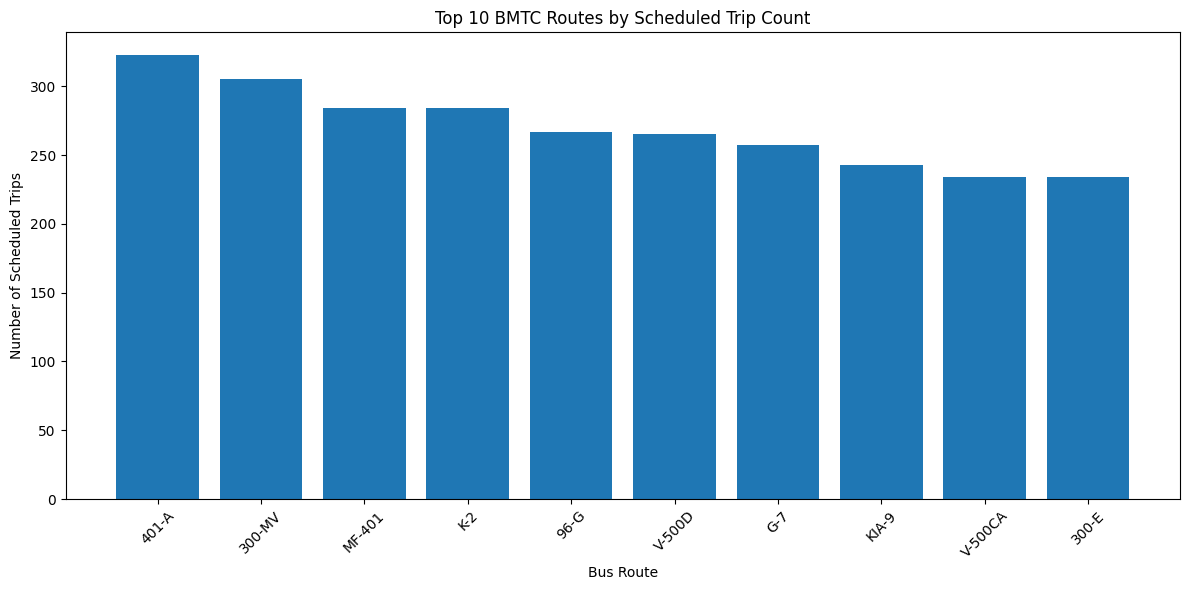

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    top_routes["route_short_name"],
    top_routes["total_trips"]
)

plt.title("Top 10 BMTC Routes by Scheduled Trip Count")
plt.xlabel("Bus Route")
plt.ylabel("Number of Scheduled Trips")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [28]:
# Count unique trips serving each bus stop

stop_activity = (
    analysis_df.groupby(["stop_id", "stop_name"])
    ["trip_id"]
    .nunique()
    .reset_index(name="total_trips")
)

# Find the top 10 busiest stops

top_stops = stop_activity.sort_values(
    by="total_trips",
    ascending=False
).head(10)

display(top_stops)

,stop_id,stop_name,total_trips
6767,62q,Kempegowda Bus Station,4858
6477,5ux,Kempegowda Bus Station,4558
6079,5k5,Corporation,2323
6618,5yq,Maharani College,2260
6546,5ws,Mysore Bank,2143
2216,2nu,KR Circle,1855
6674,607,St Marthas Hospital,1790
941,1pe,Town Hall,1639
4213,45r,KR Market (Kalasipalya),1586
4726,4jm,Banashankari Bus Station,1578


In [29]:
# Inspect both Kempegowda Bus Station records

display(
    clean_gtfs["stops.txt"][
        clean_gtfs["stops.txt"]["stop_id"].isin(["62g", "5ux"])
    ]
)

,stop_name,stop_id,stop_lat,stop_lon
4535,Kempegowda Bus Station,5ux,12.97749,77.57327
7529,Suragajakkanahalli,62g,12.73946,77.66911


In [30]:
display(
    analysis_df[
        analysis_df["stop_id"].isin(["62g", "5ux"])
    ][["stop_id", "stop_name", "trip_id"]]
    .drop_duplicates()
    .head(20)
)

,stop_id,stop_name,trip_id
8691,5ux,Kempegowda Bus Station,izf
12276,5ux,Kempegowda Bus Station,dao
12301,5ux,Kempegowda Bus Station,eb9
12454,5ux,Kempegowda Bus Station,crv
12475,5ux,Kempegowda Bus Station,grz
12496,5ux,Kempegowda Bus Station,ohd
12570,5ux,Kempegowda Bus Station,jsh
12579,62g,Suragajakkanahalli,7fw
12595,62g,Suragajakkanahalli,9xc
12611,62g,Suragajakkanahalli,kqu


Descriptive Statistics for Scheduled Stops per Trip:
count    34335.000000
mean        25.046279
std         15.269639
min          1.000000
25%         14.000000
50%         25.000000
75%         35.000000
max         95.000000
Name: stop_sequence, dtype: float64


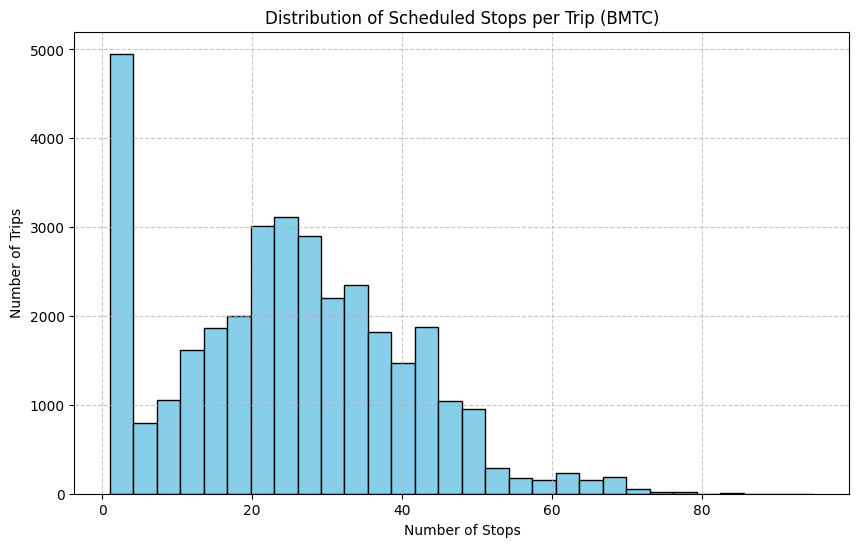

In [31]:
import matplotlib.pyplot as plt
import pandas as pd

# Calculate the number of stops per trip
stops_per_trip = clean_gtfs['stop_times.txt'].groupby('trip_id')['stop_sequence'].count()

# Print descriptive statistics
print("Descriptive Statistics for Scheduled Stops per Trip:")
print(stops_per_trip.describe())

# Plot the distribution
plt.figure(figsize=(10, 6))
plt.hist(stops_per_trip, bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Scheduled Stops per Trip (BMTC)')
plt.xlabel('Number of Stops')
plt.ylabel('Number of Trips')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [32]:
# Analyze unique values of route_type
route_types = clean_gtfs['routes.txt']['route_type'].value_counts(dropna=False)
print("Distribution of Route Types in routes.txt:")
print(route_types)

# Analyze direction_id distribution in trips
directions = clean_gtfs['trips.txt']['direction_id'].value_counts(dropna=False)
print("\nDistribution of Direction IDs in trips.txt:")
print(directions)

# Cross-tabulate route types and directions to see details
if 'route_type' in analysis_df.columns and 'direction_id' in analysis_df.columns:
    direction_by_route_type = pd.crosstab(analysis_df['route_type'], analysis_df['direction_id'])
    print("\nCross-tabulation of Route Type vs Direction ID in the merged analysis table:")
    print(direction_by_route_type)

Distribution of Route Types in routes.txt:
route_type
3    3959
Name: count, dtype: int64

Distribution of Direction IDs in trips.txt:
direction_id
1    17569
0    16766
Name: count, dtype: int64

Cross-tabulation of Route Type vs Direction ID in the merged analysis table:
direction_id       0       1
route_type                  
3             479793  380171


In [33]:
# 1. Busiest Bus Stops by unique trip count (grouped by stop name to merge multiple platforms/IDs)
busiest_stops = (
    analysis_df.groupby('stop_name')['trip_id']
    .nunique()
    .reset_index(name='unique_scheduled_trips')
    .sort_values(by='unique_scheduled_trips', ascending=False)
    .head(10)
)

# 2. Busiest Routes by scheduled trip count
busiest_routes = (
    analysis_df.groupby(['route_short_name', 'route_long_name'])['trip_id']
    .nunique()
    .reset_index(name='unique_scheduled_trips')
    .sort_values(by='unique_scheduled_trips', ascending=False)
    .head(10)
)

print("Top 10 Busiest Bus Stops (by Name):")
display(busiest_stops)

print("\nTop 10 Busiest Bus Routes:")
display(busiest_routes)

Top 10 Busiest Bus Stops (by Name):


,stop_name,unique_scheduled_trips
2608,Kempegowda Bus Station,9350
1296,Corporation,4992
2139,Indian Express,3270
2956,Maharani College,3088
4385,Town Hall,3047
3983,Shivajinagara Bus Station,2791
2368,KR Market,2776
4647,Yeshawanthapura Bus Station,2749
1953,Hebbala,2590
3146,Military Dairy Farm (Esteem Mall),2568



Top 10 Busiest Bus Routes:


,route_short_name,route_long_name,unique_scheduled_trips
2405,401-A,Yelahanka Old Town ⇔ Peenya 2nd Stage,323
1560,300-MV,Kempegowda Bus Station ⇔ Sir M Vishweshwaraiah...,305
3411,K-2,Mysore Road Bus Station ⇔ Hebbala,284
3636,MF-401,Yeshawanthapura Bus Station ⇔ Yelahanka Old Town,284
2843,96-G,Kempegowda Bus Station ⇔ Shankarnagh Bus Stand,267
3895,V-500D,Central Silk Board ⇔ Hebbala Bridge,265
3316,G-7,Kempegowda Bus Station ⇔ Janapriya Township,257
3475,KIA-9,Kempegowda Bus Station ⇔ Kempegowda Internatio...,243
3893,V-500CA,Banashankari Bus Station ⇔ ITPL,234
1551,300-E,Shivajinagara Bus Station ⇔ Krishnaraja Pura G...,234


Scheduled Stop Arrivals by Hour of Day:
00:00 - 00:59 : 338 stop events
01:00 - 01:59 : 872 stop events
02:00 - 02:59 : 932 stop events
03:00 - 03:59 : 1,046 stop events
04:00 - 04:59 : 3,357 stop events
05:00 - 05:59 : 16,533 stop events
06:00 - 06:59 : 35,418 stop events
07:00 - 07:59 : 47,527 stop events
08:00 - 08:59 : 54,267 stop events
09:00 - 09:59 : 58,188 stop events
10:00 - 10:59 : 56,985 stop events
11:00 - 11:59 : 56,747 stop events
12:00 - 12:59 : 48,716 stop events
13:00 - 13:59 : 40,089 stop events
14:00 - 14:59 : 45,379 stop events
15:00 - 15:59 : 54,552 stop events
16:00 - 16:59 : 58,952 stop events
17:00 - 17:59 : 61,446 stop events
18:00 - 18:59 : 59,616 stop events
19:00 - 19:59 : 46,954 stop events
20:00 - 20:59 : 47,709 stop events
21:00 - 21:59 : 43,611 stop events
22:00 - 22:59 : 17,686 stop events
23:00 - 23:59 : 3,044 stop events


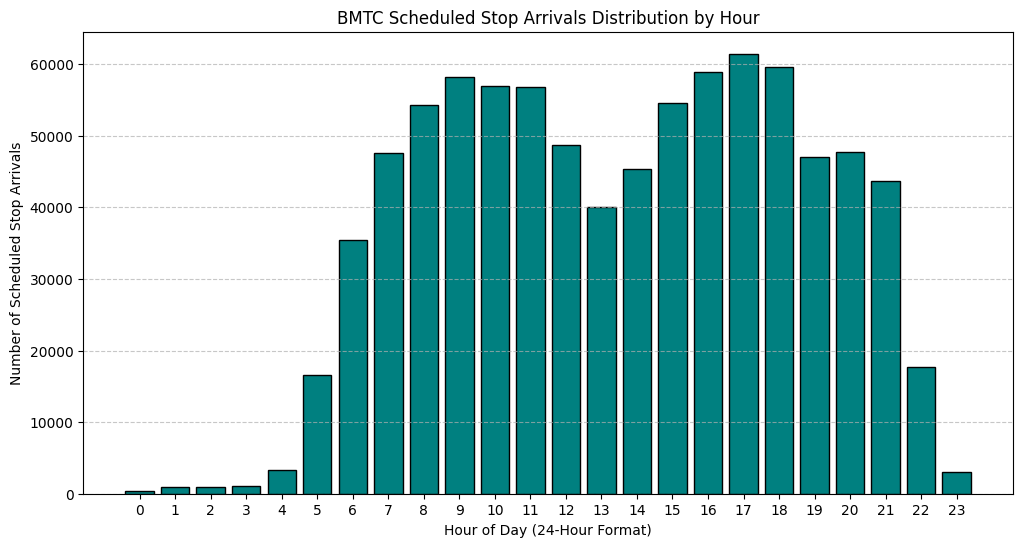

In [34]:
import matplotlib.pyplot as plt

# Extract the hour from arrival_time, handling GTFS 24h+ format (e.g., 24:15:00 -> 00 or 24)
# We'll split the arrival_time by ':' and take the first part as integer
hours = analysis_df['arrival_time'].apply(lambda x: int(x.split(':')[0]) % 24)

# Count the number of stop arrivals scheduled in each hour
hour_counts = hours.value_counts().sort_index()

print("Scheduled Stop Arrivals by Hour of Day:")
for hour, count in hour_counts.items():
    print(f"{hour:02d}:00 - {hour:02d}:59 : {count:,} stop events")

# Plot peak service hours
plt.figure(figsize=(12, 6))
plt.bar(hour_counts.index, hour_counts.values, color='teal', edgecolor='black')
plt.title('BMTC Scheduled Stop Arrivals Distribution by Hour')
plt.xlabel('Hour of Day (24-Hour Format)')
plt.ylabel('Number of Scheduled Stop Arrivals')
plt.xticks(range(0, 24))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Geographical Coordinates Range for BMTC Stops:
          stop_lat     stop_lon
count  8305.000000  8305.000000
mean     12.988341    77.584018
std       0.127263     0.128671
min      12.612210    77.140340
25%      12.906300    77.505020
50%      12.982250    77.581920
75%      13.067310    77.664650
max      13.437680    77.948700

Stops with invalid (0, 0) coordinates: 0


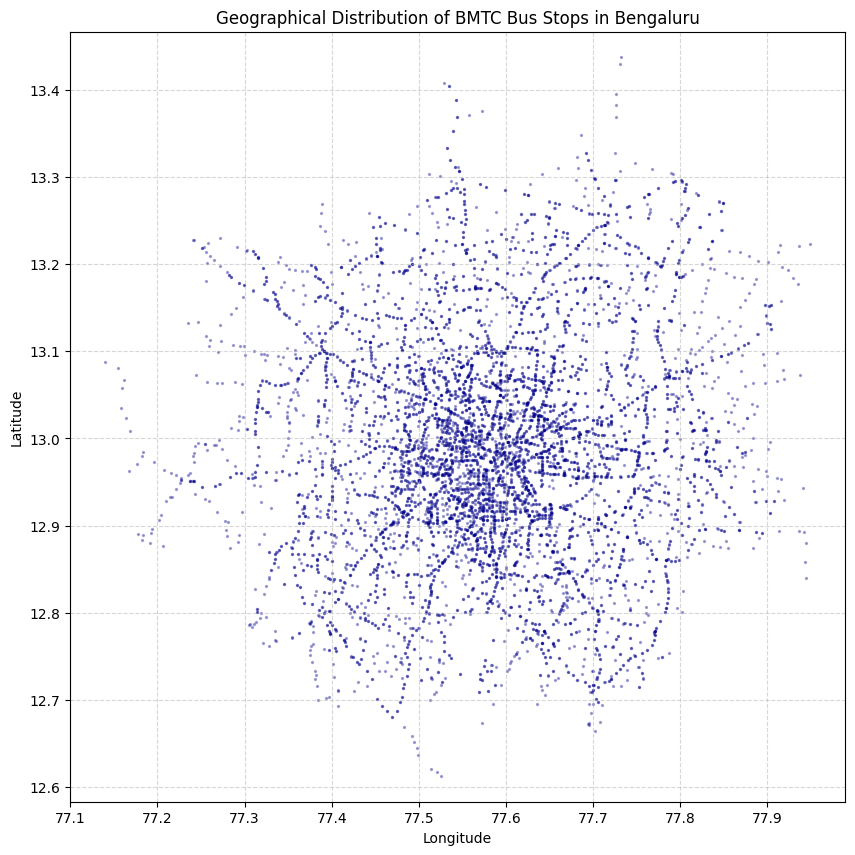

In [35]:
import matplotlib.pyplot as plt

stops_df = clean_gtfs['stops.txt']

# Calculate geographical bounding box and statistics
print("Geographical Coordinates Range for BMTC Stops:")
print(stops_df[['stop_lat', 'stop_lon']].describe())

# Check for potential data quality issues like 0.0 coordinates
invalid_coords = stops_df[(stops_df['stop_lat'] == 0) | (stops_df['stop_lon'] == 0)]
print(f"\nStops with invalid (0, 0) coordinates: {len(invalid_coords)}")

# Plot the geographical distribution of stops
plt.figure(figsize=(10, 10))
plt.scatter(stops_df['stop_lon'], stops_df['stop_lat'], alpha=0.3, s=2, color='darkblue')
plt.title('Geographical Distribution of BMTC Bus Stops in Bengaluru')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal')
plt.show()

In [36]:
# Let's check for any potential negative or zero-duration trips as a data quality check
# We will compute the start and end departure/arrival times for a few random sample trips
trip_durations = clean_gtfs['stop_times.txt'].groupby('trip_id').agg(
    start_seq=('stop_sequence', 'min'),
    end_seq=('stop_sequence', 'max'),
    start_time=('departure_time', 'min'),
    end_time=('arrival_time', 'max')
)

print("Sample Trip Durations & Boundaries:")
display(trip_durations.head(10))

Sample Trip Durations & Boundaries:


,start_seq,end_seq,start_time,end_time
trip_id,,,,
1,1,45,12:10:00,13:22:21
10,1,23,18:10:00,19:21:44
100,1,42,18:40:00,20:07:51
101,1,12,19:25:00,20:01:40
102,1,39,17:30:00,19:26:55
103,1,2,20:54:00,20:54:30
104,1,17,07:55:00,09:57:21
105,1,15,06:36:00,06:53:44
106,1,13,20:10:00,20:46:55


In [37]:
# Audit Step 1: Inspect details for stop IDs '62g' and '5ux' in stops table and merged table
stops_table = clean_gtfs['stops.txt']

# 1. Fetch records from stops.txt
print("=== Records in stops.txt ===")
display(stops_table[stops_table['stop_id'].isin(['62g', '5ux'])])

# 2. Fetch unique stop names associated with these stop IDs in analysis_df
print("\n=== Unique names and event counts in analysis_df ===")
audit_counts = (
    analysis_df[analysis_df['stop_id'].isin(['62g', '5ux'])]
    .groupby(['stop_id', 'stop_name'])
    .size()
    .reset_index(name='stop_time_record_count')
)
display(audit_counts)

=== Records in stops.txt ===


,stop_name,stop_id,stop_lat,stop_lon
4535,Kempegowda Bus Station,5ux,12.97749,77.57327
7529,Suragajakkanahalli,62g,12.73946,77.66911



=== Unique names and event counts in analysis_df ===


,stop_id,stop_name,stop_time_record_count
0,5ux,Kempegowda Bus Station,4558
1,62g,Suragajakkanahalli,31


In [38]:
# Audit Step 1b: Verify details for stop ID '62q' in stops table and analysis_df
print("=== Record for '62q' in stops.txt ===")
display(clean_gtfs['stops.txt'][clean_gtfs['stops.txt']['stop_id'] == '62q'])

print("\n=== Unique names and event count for '62q' in analysis_df ===")
display(analysis_df[analysis_df['stop_id'] == '62q'][['stop_id', 'stop_name']].drop_duplicates())

=== Record for '62q' in stops.txt ===


,stop_name,stop_id,stop_lat,stop_lon
4536,Kempegowda Bus Station,62q,12.97751,77.57141



=== Unique names and event count for '62q' in analysis_df ===


,stop_id,stop_name
8538,62q,Kempegowda Bus Station


In [39]:
# Audit Step 2: Compare count of individual stop events vs unique trip IDs per hour
hours_series = analysis_df['arrival_time'].apply(lambda x: int(x.split(':')[0]) % 24)

peak_audit = pd.DataFrame({
    'stop_events_count': hours_series.value_counts(),
    'unique_trips_count': analysis_df.groupby(hours_series)['trip_id'].nunique()
}).sort_index()

print("=== Comparison of Hourly Activity Metrics ===")
display(peak_audit)

=== Comparison of Hourly Activity Metrics ===


,stop_events_count,unique_trips_count
arrival_time,,
0,338,32
1,872,66
2,932,68
3,1046,87
4,3357,264
5,16533,1104
6,35418,2354
7,47527,3235
8,54267,3875


In [40]:
# Audit Step 3: Identify stop arrival times that are scheduled past midnight (>= 24:00:00)
over_24h_arrivals = clean_gtfs['stop_times.txt'][clean_gtfs['stop_times.txt']['arrival_time'].str.startswith(('24', '25', '26', '27', '28', '29'))]

print(f"Total records with scheduled times at or after 24:00:00: {len(over_24h_arrivals)}")
if len(over_24h_arrivals) > 0:
    print("\nSample records:")
    display(over_24h_arrivals.head(10))

Total records with scheduled times at or after 24:00:00: 0


In [41]:
# Audit Step 3b: Double-check if any time string is mathematically >= '24:00:00'
over_24h_all_arrivals = clean_gtfs['stop_times.txt'][clean_gtfs['stop_times.txt']['arrival_time'] >= '24:00:00']
over_24h_all_departures = clean_gtfs['stop_times.txt'][clean_gtfs['stop_times.txt']['departure_time'] >= '24:00:00']

print(f"Arrival times >= 24:00:00: {len(over_24h_all_arrivals)}")
print(f"Departure times >= 24:00:00: {len(over_24h_all_departures)}")

Arrival times >= 24:00:00: 0
Departure times >= 24:00:00: 0


In [42]:
# Step 1: Create a separate copy to preserve analysis_df
engineered_df = analysis_df.copy()

# Step 2: Extract scheduled arrival and departure hours as integers
engineered_df['arrival_hour'] = engineered_df['arrival_time'].apply(lambda x: int(x.split(':')[0]) % 24)
engineered_df['departure_hour'] = engineered_df['departure_time'].apply(lambda x: int(x.split(':')[0]) % 24)

# Step 3: Print engineered columns and shapes to verify
print("Preserved analysis_df shape:", analysis_df.shape)
print("New engineered_df shape:", engineered_df.shape)
print("\nSample records with new features:")
display(engineered_df[['arrival_time', 'arrival_hour', 'departure_time', 'departure_hour']].head())

Preserved analysis_df shape: (859964, 17)
New engineered_df shape: (859964, 19)

Sample records with new features:


,arrival_time,arrival_hour,departure_time,departure_hour
0,17:45:00,17,17:45:00,17
1,17:47:00,17,17:47:00,17
2,17:49:00,17,17:49:00,17
3,17:51:00,17,17:51:00,17
4,17:53:00,17,17:53:00,17


In [43]:
# Task 3 & 4: Convert arrival and departure times into minutes since midnight
def time_to_minutes(time_str):
    parts = time_str.split(':')
    return int(parts[0]) * 60 + int(parts[1])

engineered_df['arrival_minutes'] = engineered_df['arrival_time'].apply(time_to_minutes)
engineered_df['departure_minutes'] = engineered_df['departure_time'].apply(time_to_minutes)

# Task 5: Compute total scheduled trip duration (Last Stop Arrival Minutes - First Stop Departure Minutes)
trip_boundaries = engineered_df.groupby('trip_id').agg(
    trip_start_minutes=('departure_minutes', 'min'),
    trip_end_minutes=('arrival_minutes', 'max')
)
trip_boundaries['scheduled_trip_duration'] = trip_boundaries['trip_end_minutes'] - trip_boundaries['trip_start_minutes']

# Merge the duration back into the engineered_df
engineered_df = engineered_df.merge(
    trip_boundaries['scheduled_trip_duration'],
    on='trip_id',
    how='left'
)

# Verify new columns and inspect first few rows
print("New engineered_df columns:", list(engineered_df.columns[-3:]))
display(engineered_df[['trip_id', 'arrival_time', 'arrival_minutes', 'departure_time', 'departure_minutes', 'scheduled_trip_duration']].head(5))

New engineered_df columns: ['arrival_minutes', 'departure_minutes', 'scheduled_trip_duration']


,trip_id,arrival_time,arrival_minutes,departure_time,departure_minutes,scheduled_trip_duration
0,gf0,17:45:00,1065,17:45:00,1065,62
1,gf0,17:47:00,1067,17:47:00,1067,62
2,gf0,17:49:00,1069,17:49:00,1069,62
3,gf0,17:51:00,1071,17:51:00,1071,62
4,gf0,17:53:00,1073,17:53:00,1073,62


In [44]:
# Task 6: Calculate the total number of stops per trip
stops_count_per_trip = engineered_df.groupby('trip_id')['stop_sequence'].transform('count')
engineered_df['stops_per_trip'] = stops_count_per_trip

# Task 7: Calculate the total number of unique scheduled trips per route
trips_count_per_route = engineered_df.groupby('route_id')['trip_id'].transform('nunique')
engineered_df['trips_per_route'] = trips_count_per_route

# Task 8: Calculate the total number of unique scheduled trips per stop
trips_count_per_stop = engineered_df.groupby('stop_id')['trip_id'].transform('nunique')
engineered_df['trips_per_stop'] = trips_count_per_stop

# Verify the new columns
print("New engineered_df columns:", list(engineered_df.columns[-3:]))
display(engineered_df[['trip_id', 'route_id', 'stop_id', 'stops_per_trip', 'trips_per_route', 'trips_per_stop']].head(5))

New engineered_df columns: ['stops_per_trip', 'trips_per_route', 'trips_per_stop']


,trip_id,route_id,stop_id,stops_per_trip,trips_per_route,trips_per_stop
0,gf0,1p6,41c,32,1,48
1,gf0,1p6,5yq,32,1,2260
2,gf0,1p6,2nu,32,1,1855
3,gf0,1p6,607,32,1,1790
4,gf0,1p6,3xv,32,1,1123


In [45]:
import numpy as np

# Task 9: Create a readable direction label
engineered_df['direction_label'] = engineered_df['direction_id'].map({0: 'Outbound', 1: 'Inbound'})

# Task 10: Calculate Haversine distance between consecutive stops
def haversine_distance(lat1, lon1, lat2, lon2):
    # Earth radius in meters
    R = 6371000.0

    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)
    delta_phi = np.radians(lat2 - lat1)
    delta_lambda = np.radians(lon2 - lon1)

    a = np.sin(delta_phi / 2.0) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2.0) ** 2
    c = 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))

    return R * c

# Ensure rows are sorted by trip and sequence to calculate step-by-step distance
engineered_df = engineered_df.sort_values(by=['trip_id', 'stop_sequence'])

# Shift coordinate columns within each trip group to get the next stop's location
engineered_df['next_lat'] = engineered_df.groupby('trip_id')['stop_lat'].shift(-1)
engineered_df['next_lon'] = engineered_df.groupby('trip_id')['stop_lon'].shift(-1)

# Calculate distance to next stop (meters)
engineered_df['distance_to_next_stop_meters'] = haversine_distance(
    engineered_df['stop_lat'], engineered_df['stop_lon'],
    engineered_df['next_lat'], engineered_df['next_lon']
)

# Clean up temporary next location columns and fill last stop NaN distance with 0.0
engineered_df.drop(columns=['next_lat', 'next_lon'], inplace=True)
engineered_df['distance_to_next_stop_meters'] = engineered_df['distance_to_next_stop_meters'].fillna(0.0)

# Check for missing values in engineered features as a final quality validation
features_to_check = ['arrival_hour', 'departure_hour', 'arrival_minutes', 'departure_minutes',
                     'scheduled_trip_duration', 'stops_per_trip', 'trips_per_route', 'trips_per_stop',
                     'direction_label', 'distance_to_next_stop_meters']

print("=== Missing values check in engineered_df ===")
print(engineered_df[features_to_check].isnull().sum())

print("\n=== Sample Output with Complete Features ===")
display(engineered_df[['trip_id', 'stop_sequence', 'stop_name', 'direction_label', 'distance_to_next_stop_meters']].head(5))

=== Missing values check in engineered_df ===
arrival_hour                    0
departure_hour                  0
arrival_minutes                 0
departure_minutes               0
scheduled_trip_duration         0
stops_per_trip                  0
trips_per_route                 0
trips_per_stop                  0
direction_label                 0
distance_to_next_stop_meters    0
dtype: int64

=== Sample Output with Complete Features ===


,trip_id,stop_sequence,stop_name,direction_label,distance_to_next_stop_meters
769368,1,1,Shivajinagara Bus Station,Outbound,637.715653
769369,1,2,Indian Express,Outbound,526.305365
769370,1,3,Cunningham Road,Outbound,552.142038
769371,1,4,Vasantha Nagara,Outbound,903.283945
769372,1,5,Bamboo Bazaar,Outbound,558.581003


In [46]:
import numpy as np
import pandas as pd

# 1. Create a fresh copy of analysis_df to preserve it unchanged
engineered_df = analysis_df.copy()

# Helper function to convert time string HH:MM:SS to minutes since midnight
def time_str_to_minutes(time_str):
    parts = time_str.split(':')
    return int(parts[0]) * 60 + int(parts[1]) + int(parts[2]) / 60.0

# 2. Add raw arrival and departure minutes for all stop events
engineered_df['arrival_minutes'] = engineered_df['arrival_time'].apply(time_str_to_minutes)
engineered_df['departure_minutes'] = engineered_df['departure_time'].apply(time_str_to_minutes)

# Extract basic hour features (as integer hour of day)
engineered_df['arrival_hour'] = engineered_df['arrival_time'].apply(lambda x: int(x.split(':')[0]) % 24)
engineered_df['departure_hour'] = engineered_df['departure_time'].apply(lambda x: int(x.split(':')[0]) % 24)

# 3. Recalculate scheduled trip duration based strictly on first and last stop_sequence
print("Calculating precise scheduled trip durations...")
# Find the index of the first and last stops for each trip
first_stop_idx = engineered_df.groupby('trip_id')['stop_sequence'].idxmin()
last_stop_idx = engineered_df.groupby('trip_id')['stop_sequence'].idxmax()

# Extract departure minutes of first stop and arrival minutes of last stop
trip_starts = engineered_df.loc[first_stop_idx, ['trip_id', 'departure_minutes']].rename(columns={'departure_minutes': 'trip_start_minutes'})
trip_ends = engineered_df.loc[last_stop_idx, ['trip_id', 'arrival_minutes']].rename(columns={'arrival_minutes': 'trip_end_minutes'})

# Merge and compute precise duration
trip_durations = pd.merge(trip_starts, trip_ends, on='trip_id')
trip_durations['scheduled_trip_duration'] = trip_durations['trip_end_minutes'] - trip_durations['trip_start_minutes']

# Merge this precise duration back into engineered_df
engineered_df = engineered_df.merge(trip_durations[['trip_id', 'scheduled_trip_duration']], on='trip_id', how='left')

# 4. Verify/Re-calculate trip-level and route-level frequency metrics using transform
engineered_df['stops_per_trip'] = engineered_df.groupby('trip_id')['stop_id'].transform('count')
engineered_df['trips_per_route'] = engineered_df.groupby('route_id')['trip_id'].transform('nunique')
engineered_df['trips_per_stop'] = engineered_df.groupby('stop_id')['trip_id'].transform('nunique')

# 5. Calculate Haversine straight-line distance to next stop
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371000.0  # Earth radius in meters
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    delta_phi = np.radians(lat2 - lat1)
    delta_lambda = np.radians(lon2 - lon1)
    a = np.sin(delta_phi / 2.0) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2.0) ** 2
    c = 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))
    return R * c

# Sort by trip and sequence to guarantee sequential order
engineered_df = engineered_df.sort_values(by=['trip_id', 'stop_sequence'])

# Shift coordinate columns within each trip group to get the next stop's location
engineered_df['next_lat'] = engineered_df.groupby('trip_id')['stop_lat'].shift(-1)
engineered_df['next_lon'] = engineered_df.groupby('trip_id')['stop_lon'].shift(-1)

# Compute straight-line distance
engineered_df['straight_line_distance_next_stop_meters'] = haversine_distance(
    engineered_df['stop_lat'], engineered_df['stop_lon'],
    engineered_df['next_lat'], engineered_df['next_lon']
)

# Clean up temporary shift columns
engineered_df.drop(columns=['next_lat', 'next_lon'], inplace=True)

# The final stop of each trip has no next stop, so we fill the NaN with 0.0
engineered_df['straight_line_distance_next_stop_meters'] = engineered_df['straight_line_distance_next_stop_meters'].fillna(0.0)

# 6. Final verification
print("\n=== Verification of Engineered Features ===")
print(f"Original analysis_df columns count: {len(analysis_df.columns)}")
print(f"New engineered_df shape: {engineered_df.shape}")
print(f"Missing values in scheduled_trip_duration: {engineered_df['scheduled_trip_duration'].isnull().sum()}")
print(f"Missing values in straight_line_distance_next_stop_meters: {engineered_df['straight_line_distance_next_stop_meters'].isnull().sum()}")

display(engineered_df[['trip_id', 'stop_sequence', 'stop_name', 'direction_id', 'scheduled_trip_duration', 'straight_line_distance_next_stop_meters']].head(5))

Calculating precise scheduled trip durations...

=== Verification of Engineered Features ===
Original analysis_df columns count: 17
New engineered_df shape: (859964, 26)
Missing values in scheduled_trip_duration: 0
Missing values in straight_line_distance_next_stop_meters: 0


,trip_id,stop_sequence,stop_name,direction_id,scheduled_trip_duration,straight_line_distance_next_stop_meters
769368,1,1,Shivajinagara Bus Station,0,72.35,637.715653
769369,1,2,Indian Express,0,72.35,526.305365
769370,1,3,Cunningham Road,0,72.35,552.142038
769371,1,4,Vasantha Nagara,0,72.35,903.283945
769372,1,5,Bamboo Bazaar,0,72.35,558.581003


=== Top 10 Routes with Longest Average Scheduled Trip Durations ===


,route_short_name,route_long_name,min_duration_mins,avg_duration_mins,max_duration_mins,trip_count
3904,V-BENGALURU DARSHINI,Kempegowda Bus Station ⇔ Kempegowda Bus Station,597.800000,597.800000,597.800000,50
3471,KIA-8C,Chandapura ⇔ Kempegowda International Airport,175.700000,181.055848,187.283333,1596
2598,500-DG,Nelamangala Bus Station ⇔ Central Silk Board,177.533333,177.533333,177.533333,584
709,248-Z,Mysore Road Bus Station ⇔ Kanasawadi,167.333333,167.333333,167.333333,128
841,256-MB,KR Market ⇔ Magadi,163.183333,163.183333,163.183333,91
2597,500-DC D38G-BELF,Depot-38 Gate ⇔ BEL Factory,159.900000,159.900000,159.900000,40
1947,335-N RRC-KBS-KDG,RR Medical College ⇔ Kadugodi Bus Station,158.166667,158.166667,158.166667,88
1445,293-ZA,Kempegowda Bus Station ⇔ Vijayapura Bus Stand ...,138.300000,149.416667,163.000000,664
2381,398-H D27G-HSK,Depot-27 Gate ⇔ Hosakote Bus Stand (Old),143.916667,148.190000,157.850000,70
577,240-K,KR Market (Kalasipalya) ⇔ Biskur,148.050000,148.050000,148.050000,77


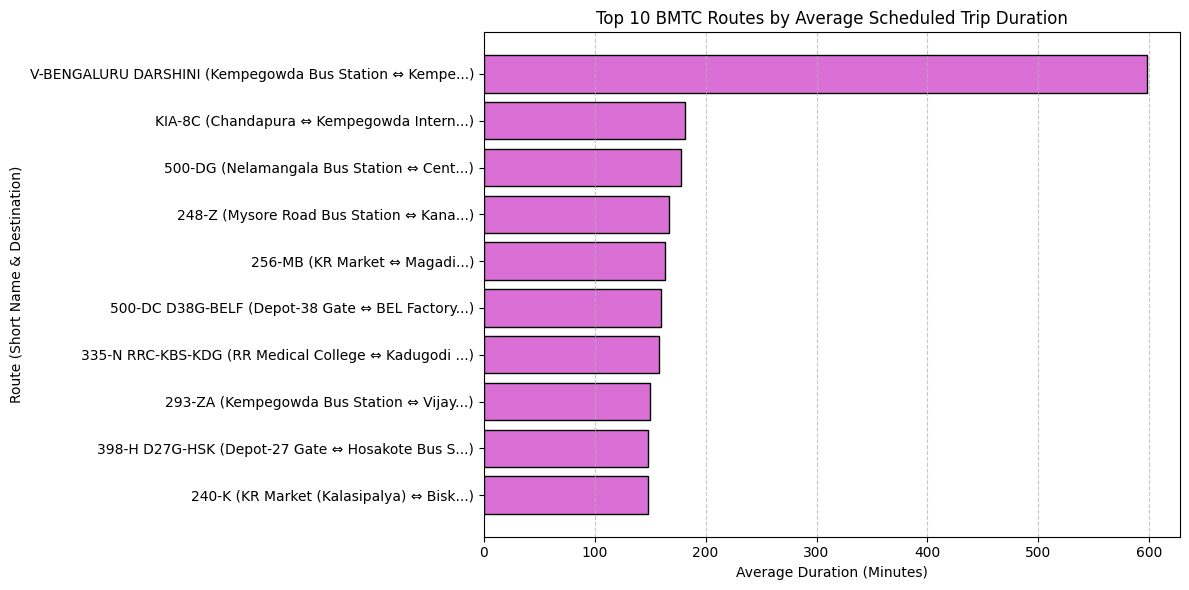

In [47]:
import matplotlib.pyplot as plt

# 1. Group by route to compare scheduled trip durations
route_duration_stats = (
    engineered_df.groupby(['route_short_name', 'route_long_name'])['scheduled_trip_duration']
    .agg(['min', 'mean', 'max', 'count'])
    .reset_index()
    .rename(columns={'min': 'min_duration_mins', 'mean': 'avg_duration_mins', 'max': 'max_duration_mins', 'count': 'trip_count'})
)

# Sort to find the routes with the longest average scheduled trip durations
top_longest_routes = route_duration_stats.sort_values(by='avg_duration_mins', ascending=False).head(10)

print("=== Top 10 Routes with Longest Average Scheduled Trip Durations ===")
display(top_longest_routes)

# Plot the average scheduled durations for these top 10 routes
plt.figure(figsize=(12, 6))
plt.barh(top_longest_routes['route_short_name'] + " (" + top_longest_routes['route_long_name'].str[:30] + "...)",
         top_longest_routes['avg_duration_mins'], color='orchid', edgecolor='black')
plt.gca().invert_yaxis()
plt.title('Top 10 BMTC Routes by Average Scheduled Trip Duration')
plt.xlabel('Average Duration (Minutes)')
plt.ylabel('Route (Short Name & Destination)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [48]:
# Filter out trips with 0 duration to avoid placeholder errors
valid_trips_df = engineered_df[engineered_df['scheduled_trip_duration'] > 0]

# Find the rows representing the absolute longest and shortest trips
longest_trip_idx = valid_trips_df['scheduled_trip_duration'].idxmax()
shortest_trip_idx = valid_trips_df['scheduled_trip_duration'].idxmin()

longest_trip = valid_trips_df.loc[longest_trip_idx]
shortest_trip = valid_trips_df.loc[shortest_trip_idx]

print("=== Absolute Longest Scheduled Trip ===")
print(f"Trip ID: {longest_trip['trip_id']}")
print(f"Route: {longest_trip['route_short_name']} ({longest_trip['route_long_name']})")
print(f"Duration: {longest_trip['scheduled_trip_duration']:.2f} minutes")
print(f"Stops: {longest_trip['stops_per_trip']}")

print("\n=== Absolute Shortest Scheduled Trip ===")
print(f"Trip ID: {shortest_trip['trip_id']}")
print(f"Route: {shortest_trip['route_short_name']} ({shortest_trip['route_long_name']})")
print(f"Duration: {shortest_trip['scheduled_trip_duration']:.2f} minutes")
print(f"Stops: {shortest_trip['stops_per_trip']}")

=== Absolute Longest Scheduled Trip ===
Trip ID: m6j
Route: V-BENGALURU DARSHINI (Kempegowda Bus Station ⇔ Kempegowda Bus Station)
Duration: 597.80 minutes
Stops: 50

=== Absolute Shortest Scheduled Trip ===
Trip ID: 103
Route: D37-KGR (Depot-37 Kengeri ⇔ Kengeri Bus Station)
Duration: 0.50 minutes
Stops: 2


=== Top 10 Routes with the Most Unique Stops ===


,route_short_name,route_long_name,unique_stops_count
3472,KIA-8D,Sarjapura ⇔ Kempegowda International Airport,145
2446,401-R,BEML Layout 5th stage ⇔ Yelahanka Old Town,131
579,240-MA,KR Market (Kalasipalya) ⇔ Magadi,128
1520,298-MP,Kempegowda Bus Station ⇔ Vijayapura Bus Stand ...,122
1525,298-MV,KR Market ⇔ Vijayapura Bus Stand Jangamakote,122
2641,501-A,Banashankari Bus Station ⇔ Hebbala Bridge,112
3471,KIA-8C,Chandapura ⇔ Kempegowda International Airport,112
3882,V-356M,Kempegowda Bus Station ⇔ Anekal,100
1500,298-M,Kempegowda Bus Station ⇔ Devanahalli Old Bus S...,98
576,240-J,KR Market (Kalasipalya) ⇔ Chikka Maskal,96


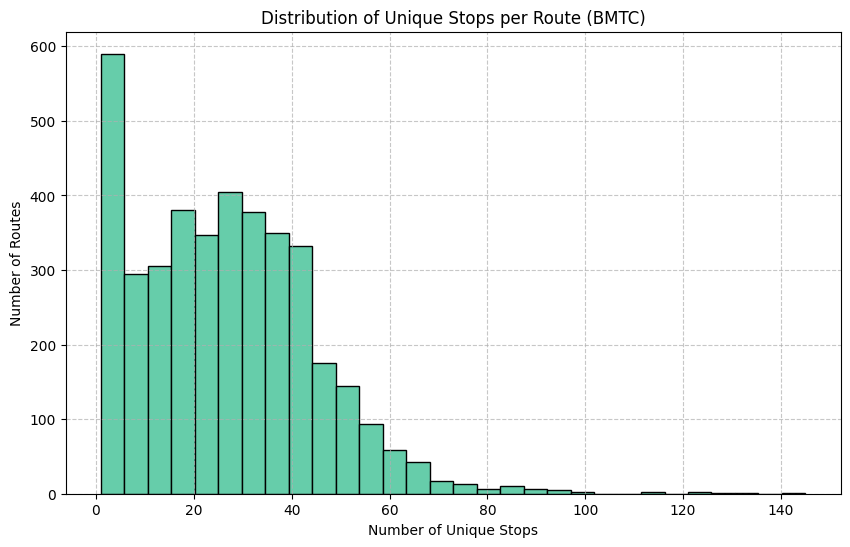

In [49]:
import matplotlib.pyplot as plt

# Group by route to find the unique stop count per route
route_stop_counts = (
    engineered_df.groupby(['route_short_name', 'route_long_name'])['stop_id']
    .nunique()
    .reset_index(name='unique_stops_count')
)

# Find the top 10 routes with the highest number of unique stops
top_stops_routes = route_stop_counts.sort_values(by='unique_stops_count', ascending=False).head(10)

print("=== Top 10 Routes with the Most Unique Stops ===")
display(top_stops_routes)

# Plot the distribution of stop counts across all routes
plt.figure(figsize=(10, 6))
plt.hist(route_stop_counts['unique_stops_count'], bins=30, color='mediumaquamarine', edgecolor='black')
plt.title('Distribution of Unique Stops per Route (BMTC)')
plt.xlabel('Number of Unique Stops')
plt.ylabel('Number of Routes')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

=== Scheduled Service Distribution by Time Period ===


,time_period,stop_events_count,percentage
0,Late Night (00:00-04:00),3188,0.370713
1,Early Morning (04:00-07:00),55308,6.431432
2,Morning Peak (07:00-11:00),216967,25.229777
3,Midday / Afternoon (11:00-16:00),245483,28.545730
4,Evening Peak (16:00-20:00),226968,26.392733
5,Night (20:00-24:00),112050,13.029615


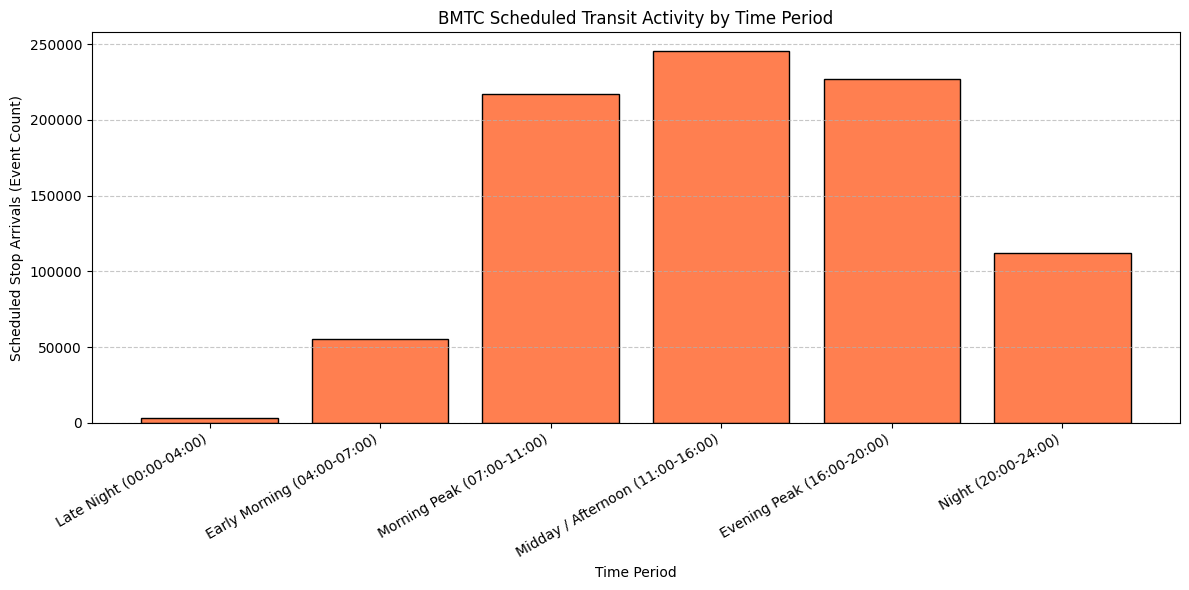

In [50]:
import matplotlib.pyplot as plt
import pandas as pd

# Define a function to map hours into service time periods
def assign_time_period(hour):
    if 4 <= hour < 7:
        return 'Early Morning (04:00-07:00)'
    elif 7 <= hour < 11:
        return 'Morning Peak (07:00-11:00)'
    elif 11 <= hour < 16:
        return 'Midday / Afternoon (11:00-16:00)'
    elif 16 <= hour < 20:
        return 'Evening Peak (16:00-20:00)'
    elif 20 <= hour < 24:
        return 'Night (20:00-24:00)'
    else:
        return 'Late Night (00:00-04:00)'

# Apply mapping to engineered_df
engineered_df['time_period'] = engineered_df['arrival_hour'].apply(assign_time_period)

# Calculate frequency and percentage
time_period_distribution = (
    engineered_df['time_period']
    .value_counts()
    .reindex([
        'Late Night (00:00-04:00)',
        'Early Morning (04:00-07:00)',
        'Morning Peak (07:00-11:00)',
        'Midday / Afternoon (11:00-16:00)',
        'Evening Peak (16:00-20:00)',
        'Night (20:00-24:00)'
    ])
    .reset_index(name='stop_events_count')
)
time_period_distribution['percentage'] = (time_period_distribution['stop_events_count'] / time_period_distribution['stop_events_count'].sum()) * 100

print("=== Scheduled Service Distribution by Time Period ===")
display(time_period_distribution)

# Visualize the distribution
plt.figure(figsize=(12, 6))
plt.bar(time_period_distribution['time_period'], time_period_distribution['stop_events_count'], color='coral', edgecolor='black')
plt.title('BMTC Scheduled Transit Activity by Time Period')
plt.xlabel('Time Period')
plt.ylabel('Scheduled Stop Arrivals (Event Count)')
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

=== Direction-wise Service Comparisons ===


,direction_id,total_scheduled_trips,avg_stops_per_trip,avg_duration_minutes
0,0,16766,35.311497,76.807981
1,1,17569,33.148423,74.655697


/tmp/ipykernel_4905/3194317309.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([


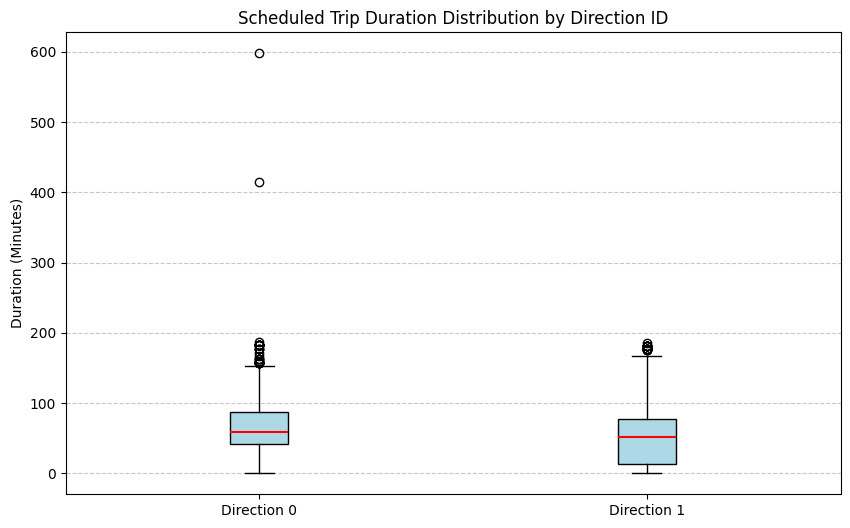

In [51]:
import matplotlib.pyplot as plt
import pandas as pd

# Group unique trips by direction_id to compare key transit characteristics
direction_comparisons = engineered_df.groupby('direction_id').agg(
    total_scheduled_trips=('trip_id', 'nunique'),
    avg_stops_per_trip=('stops_per_trip', 'mean'),
    avg_duration_minutes=('scheduled_trip_duration', 'mean')
).reset_index()

print("=== Direction-wise Service Comparisons ===")
display(direction_comparisons)

# Visualize the distribution of scheduled trip durations by direction using a boxplot
plt.figure(figsize=(10, 6))
# Get unique trips for duration plotting to avoid skewing by stop events
trip_level_df = engineered_df.drop_duplicates(subset=['trip_id'])

plt.boxplot([
    trip_level_df[trip_level_df['direction_id'] == 0]['scheduled_trip_duration'],
    trip_level_df[trip_level_df['direction_id'] == 1]['scheduled_trip_duration']
], labels=['Direction 0', 'Direction 1'], patch_artist=True,
   boxprops=dict(facecolor='lightblue', color='black'),
   medianprops=dict(color='red', linewidth=1.5))

plt.title('Scheduled Trip Duration Distribution by Direction ID')
plt.ylabel('Duration (Minutes)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

=== Geographic Stop Boundaries ===
Latitude Range: 12.61221 to 13.43768
Longitude Range: 77.14034 to 77.94870


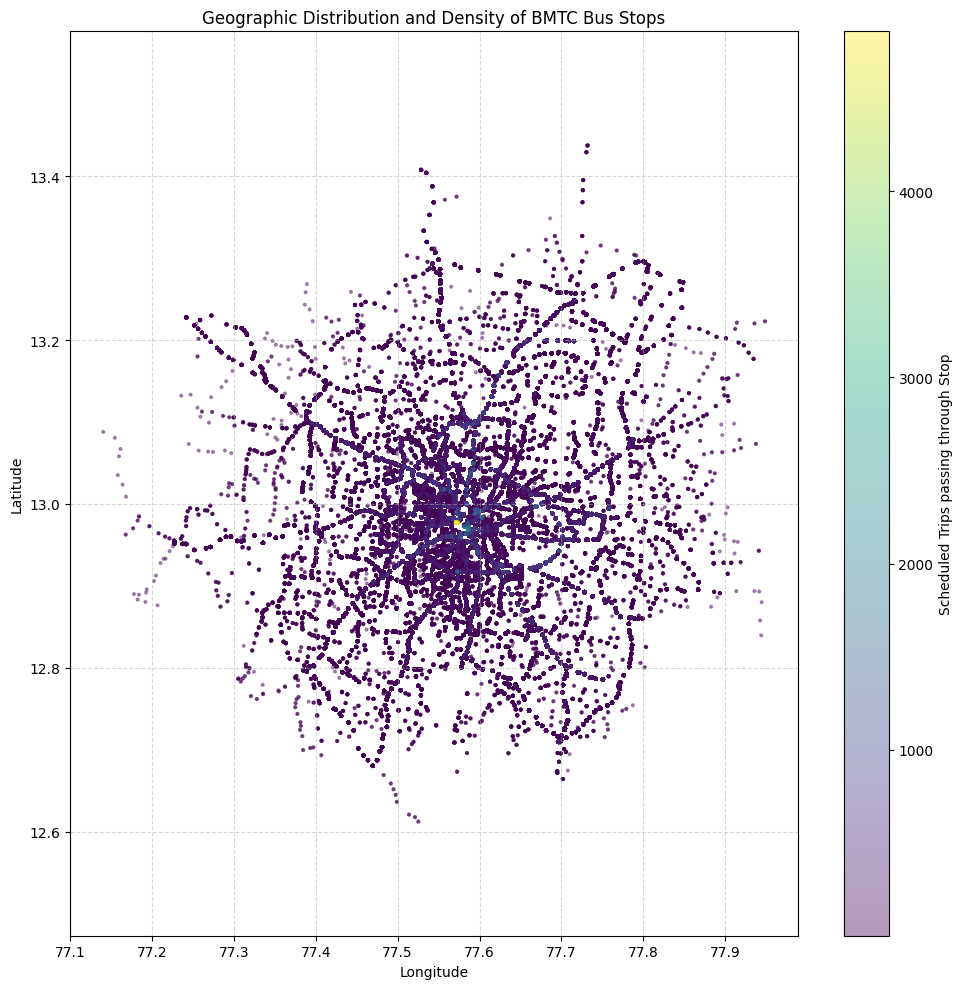

In [52]:
import matplotlib.pyplot as plt

# Analyze geographic spread and identify outliers using coordinate columns
print("=== Geographic Stop Boundaries ===")
lat_min, lat_max = engineered_df['stop_lat'].min(), engineered_df['stop_lat'].max()
lon_min, lon_max = engineered_df['stop_lon'].min(), engineered_df['stop_lon'].max()

print(f"Latitude Range: {lat_min:.5f} to {lat_max:.5f}")
print(f"Longitude Range: {lon_min:.5f} to {lon_max:.5f}")

# Plot geographic scatter of bus stops weighted by trip counts
plt.figure(figsize=(10, 10))
scatter = plt.scatter(
    engineered_df['stop_lon'],
    engineered_df['stop_lat'],
    c=engineered_df['trips_per_stop'],
    cmap='viridis',
    alpha=0.4,
    s=4
)
plt.colorbar(scatter, label='Scheduled Trips passing through Stop')
plt.title('Geographic Distribution and Density of BMTC Bus Stops')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal')
plt.tight_layout()
plt.show()

=== Transit Concentration Summary ===
Route-Level Trips: Median=2.0, Mean=8.7, Max=323
Stop-Level Trips:  Median=19.0, Mean=103.5, Max=4858


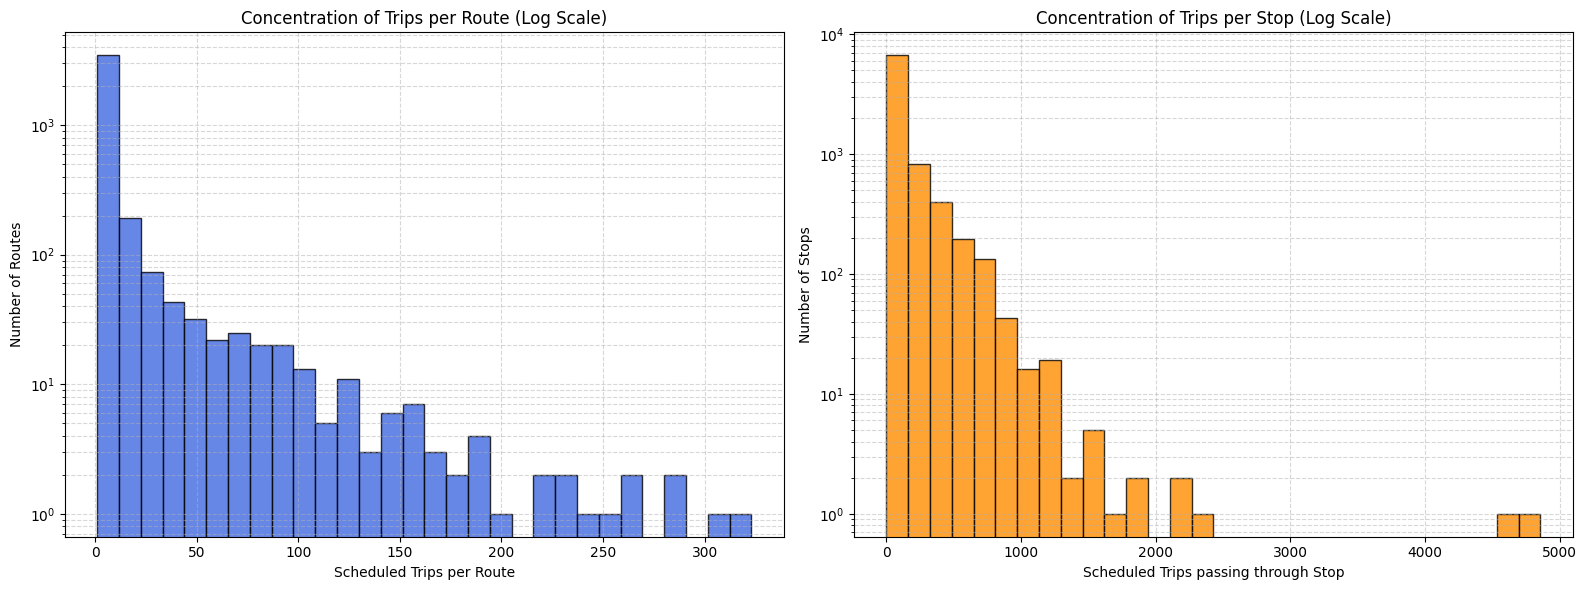

In [53]:
import matplotlib.pyplot as plt
import numpy as np

# Extract unique trip stats per route and per stop
route_activity = engineered_df.drop_duplicates(subset=['route_id'])['trips_per_route']
stop_activity = engineered_df.drop_duplicates(subset=['stop_id'])['trips_per_stop']

print("=== Transit Concentration Summary ===")
print(f"Route-Level Trips: Median={route_activity.median():.1f}, Mean={route_activity.mean():.1f}, Max={route_activity.max()}")
print(f"Stop-Level Trips:  Median={stop_activity.median():.1f}, Mean={stop_activity.mean():.1f}, Max={stop_activity.max()}")

# Plot distribution curves for both metrics side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: Routes
axes[0].hist(route_activity, bins=30, color='royalblue', edgecolor='black', alpha=0.8, log=True)
axes[0].set_title('Concentration of Trips per Route (Log Scale)')
axes[0].set_xlabel('Scheduled Trips per Route')
axes[0].set_ylabel('Number of Routes')
axes[0].grid(True, which="both", linestyle='--', alpha=0.5)

# Right Plot: Stops
axes[1].hist(stop_activity, bins=30, color='darkorange', edgecolor='black', alpha=0.8, log=True)
axes[1].set_title('Concentration of Trips per Stop (Log Scale)')
axes[1].set_xlabel('Scheduled Trips passing through Stop')
axes[1].set_ylabel('Number of Stops')
axes[1].grid(True, which="both", linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Preparing the Stop-Level Features for Unsupervised Clustering

Before training a clustering model, we must construct a stop-level feature matrix. We will aggregate details from `engineered_df` to create the following features for each unique stop:
1. `trips_per_stop`: Total passing scheduled trips.
2. `route_count_per_stop`: Number of unique routes serving the stop.
3. `stop_lat` & `stop_lon`: Spatial coordinates.

Let's extract and inspect this matrix to make sure there are no missing values.

In [54]:
import pandas as pd

# Aggregate features at the unique stop level from our verified engineered_df
stop_features = engineered_df.groupby(['stop_id', 'stop_name']).agg(
    scheduled_trips_count=('trip_id', 'nunique'),
    unique_routes_count=('route_id', 'nunique'),
    latitude=('stop_lat', 'mean'),
    longitude=('stop_lon', 'mean')
).reset_index()

print("=== Stop-Level Feature Matrix Shape ===")
print(stop_features.shape)

print("\n=== Missing Values Check ===")
print(stop_features.isnull().sum())

print("\n=== First 5 Rows of Stop Feature Matrix ===")
display(stop_features.head())


=== Stop-Level Feature Matrix Shape ===
(8305, 6)

=== Missing Values Check ===
stop_id                  0
stop_name                0
scheduled_trips_count    0
unique_routes_count      0
latitude                 0
longitude                0
dtype: int64

=== First 5 Rows of Stop Feature Matrix ===


,stop_id,stop_name,scheduled_trips_count,unique_routes_count,latitude,longitude
0,1,BP Indian School Nelamangala,7,6,13.08764,77.37555
1,10,Thore Nagasandra Cross,122,23,13.11196,77.48188
2,100,Chinnaswamy Stadium,71,9,12.97742,77.59885
3,101,Depot-14 RT Nagara,90,4,13.02868,77.59328
4,102,Vijayanagara,129,9,12.97433,77.53843


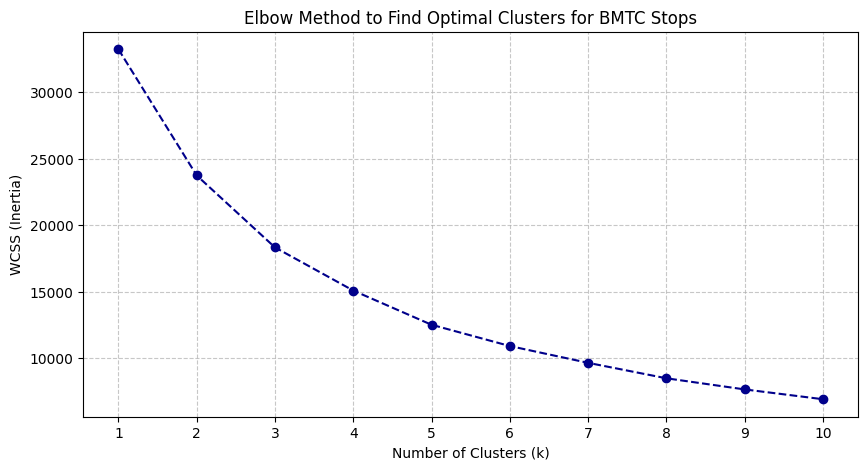

=== Cluster Distribution ===
cluster
1    2999
2    2263
0    2256
3     787
Name: count, dtype: int64

=== Sample Cluster Profiles (Average Values) ===


,cluster,stops_count,avg_trips,avg_routes,avg_lat,avg_lon
0,0,2256,52.506206,6.169770,13.065107,77.465788
1,1,2999,60.981994,7.607536,12.869151,77.570546
2,2,2263,49.419797,7.205921,13.071315,77.715593
3,3,787,567.701398,65.944091,12.983890,77.595929


In [55]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Select and scale the features for clustering
clustering_features = ['scheduled_trips_count', 'unique_routes_count', 'latitude', 'longitude']
X = stop_features[clustering_features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Determine the optimal number of clusters using the Elbow Method
wcss = []
cluster_range = range(1, 11)

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# 3. Plot the Elbow Curve
plt.figure(figsize=(10, 5))
plt.plot(cluster_range, wcss, marker='o', linestyle='--', color='darkblue')
plt.title('Elbow Method to Find Optimal Clusters for BMTC Stops')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(cluster_range)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# 4. Fit K-Means with an optimal value of k=4 (typical for capturing high, medium, low, and outer/suburban stops)
optimal_k = 4
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
stop_features['cluster'] = kmeans_model.fit_transform(X_scaled).argmin(axis=1)

print("=== Cluster Distribution ===")
print(stop_features['cluster'].value_counts())

print("\n=== Sample Cluster Profiles (Average Values) ===")
profile = stop_features.groupby('cluster').agg(
    stops_count=('stop_id', 'count'),
    avg_trips=('scheduled_trips_count', 'mean'),
    avg_routes=('unique_routes_count', 'mean'),
    avg_lat=('latitude', 'mean'),
    avg_lon=('longitude', 'mean')
).reset_index()
display(profile)